In [2]:
import json, os, glob
import pandas as pd

BASE = '/Users/user/Documents/UCF/Thesis/KBootRepair/workspace/samples/x86_64 gemini-3.1-pro repaired'

with open(f'{BASE}/results.json') as f:
    results = json.load(f)
duration_map = {
    os.path.basename(os.path.dirname(os.path.dirname(r['path']))): r['duration']
    for r in results['samples']
}

rows = []
for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
    summary_path = f'{sample_dir}/agent_repair/summary.json'
    if not os.path.exists(summary_path):
        continue
    with open(summary_path) as f:
        data = json.load(f)

    s = data['summary']
    attempts = data.get('attempts', [])
    name = os.path.basename(sample_dir)

    rows.append({
        'sample':          name,
        'final_status':    s['status'],
        'total_attempts':  s['attempts'],
        'edit_distance':   s.get('edit_distance'),
        'input_tokens':    sum(a['token_usage'].get('input_tokens', 0) for a in attempts),
        'output_tokens':   sum(a['token_usage'].get('output_tokens', 0) for a in attempts),
        'build_time':      sum(a['summary'].get('build_time', 0) for a in attempts),
        'boot_time':       sum(a['summary'].get('boot_time', 0) for a in attempts),
        'llm_time':        sum(a['summary'].get('llm_time', 0) for a in attempts),
        'tool_calls':      sum(a['summary'].get('tool_call_count', 0) for a in attempts),
        'wall_clock':      duration_map.get(name),
    })

samples = pd.DataFrame(rows)
samples['sample_num'] = samples['sample'].str.extract(r'(\d+)$').astype(int)
samples['remaining_time'] = samples['wall_clock'] - samples['build_time'] - samples['boot_time'] - samples['llm_time']
samples = samples.sort_values('sample_num').reset_index(drop=True)

print(samples.shape)
samples.head()

(50, 13)


,sample,final_status,total_attempts,edit_distance,input_tokens,output_tokens,build_time,boot_time,llm_time,tool_calls,wall_clock,sample_num,remaining_time
0,sample_0,success,16,2629,3061379,102456,9796.543696,3731.744774,1827.223409,223,17831.86,0,2476.348122
1,sample_1,max-attempts-reached,20,-1,5539100,229761,18524.618227,5473.444652,2830.788146,299,30884.49,1,4055.638974
2,sample_2,success,7,1663,655870,34274,7502.736501,1556.780613,548.324725,85,10483.26,2,875.418160
3,sample_3,success,19,3736,4430313,171301,32467.373803,4304.806870,2813.822942,269,49282.11,3,9696.106385
4,sample_4,success,6,1803,1360067,54781,9919.672275,1244.247249,661.017890,88,12925.27,4,1100.332586


# Success Rate

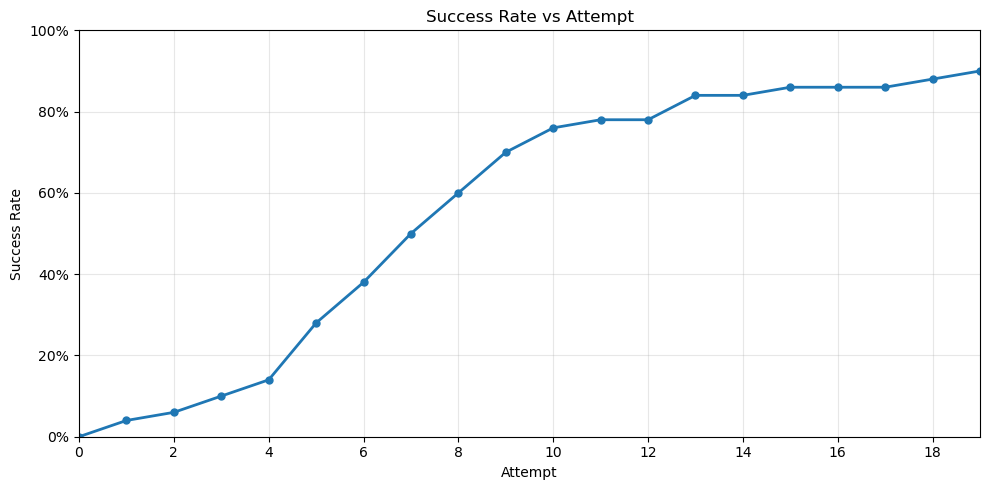

In [3]:
# Success Rate vs Attempt

import matplotlib.pyplot as plt

successful = samples[samples['final_status'] == 'success']
first_success = successful.set_index('sample')['total_attempts'] - 1

n_samples = len(samples)
max_attempt = samples['total_attempts'].max() - 1

attempts = range(0, max_attempt + 1)
success_rate = [first_success.le(n).sum() / n_samples for n in attempts]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(attempts, success_rate, marker='o', linewidth=2, markersize=5)

ax.set_xlabel('Attempt')
ax.set_ylabel('Success Rate')
ax.set_title('Success Rate vs Attempt')
ax.set_xlim(0, max_attempt)
ax.set_ylim(0, 1)
ax.set_xticks(range(0, max_attempt + 1, 2))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
print('25th Percentile:', samples['total_attempts'].quantile(0.25))
print('50th Percentile:', samples['total_attempts'].quantile(0.50))
print('75th Percentile:', samples['total_attempts'].quantile(0.75))

25th Percentile: 6.0
50th Percentile: 8.5
75th Percentile: 11.0


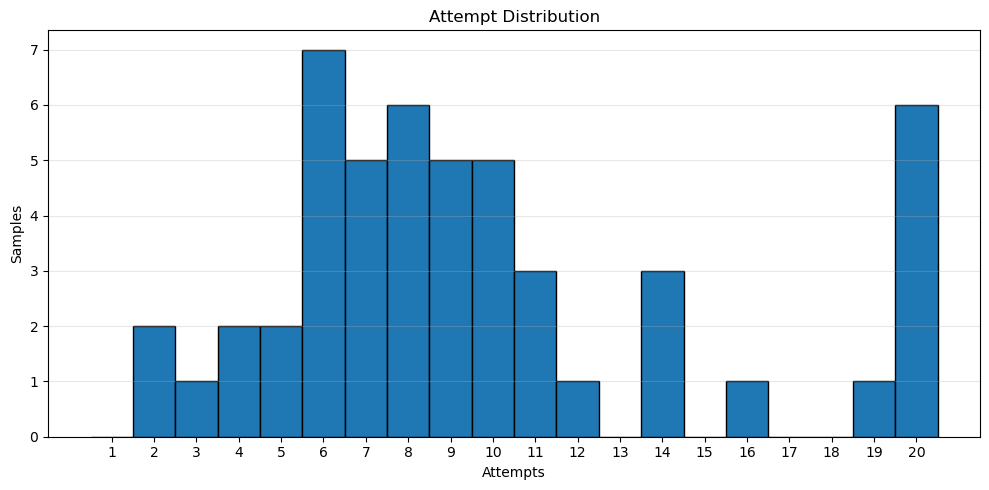

In [5]:
per_sample = samples.drop_duplicates('sample')

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(per_sample['total_attempts'], bins=range(1, per_sample['total_attempts'].max() + 2), edgecolor='black', align='left')

ax.set_xlabel('Attempts')
ax.set_ylabel('Samples')
ax.set_title('Attempt Distribution')
ax.set_xticks(range(1, per_sample['total_attempts'].max() + 1))
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [6]:
print('Mean Attempt:', per_sample['total_attempts'].mean())
print('Standard Deviation Attempt:', per_sample['total_attempts'].std())
print()

print('Min Attempt:', per_sample['total_attempts'].min())
print('1st Quartile Attempt:', per_sample['total_attempts'].quantile(0.25))
print('Median Attempt:', per_sample['total_attempts'].median())
print('3rd Quartile Attempt:', per_sample['total_attempts'].quantile(0.75))
print('Max Attempt:', per_sample['total_attempts'].max())

Mean Attempt: 9.74
Standard Deviation Attempt: 5.058070939859688

Min Attempt: 2
1st Quartile Attempt: 6.0
Median Attempt: 8.5
3rd Quartile Attempt: 11.0
Max Attempt: 20


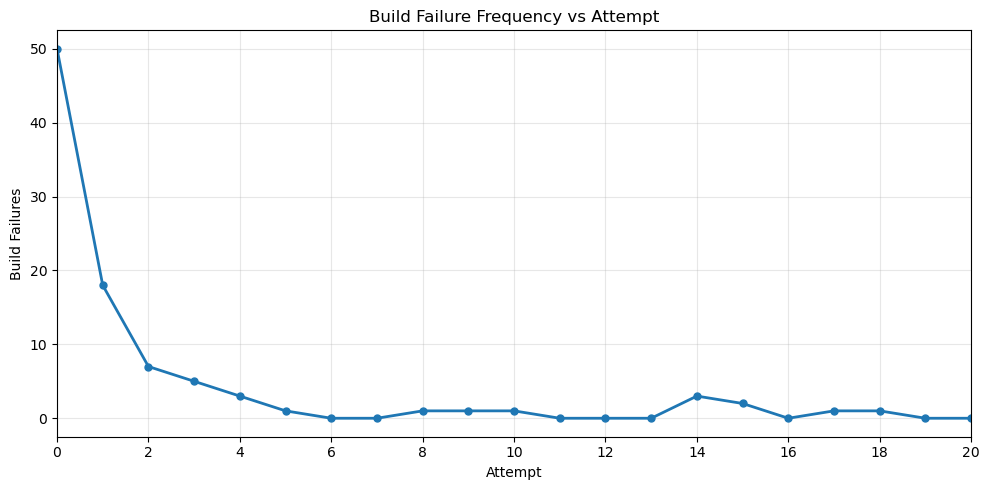

In [7]:
# Build Failure Frequency vs Attempt

attempt_rows = []
for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
    summary_path = f'{sample_dir}/agent_repair/summary.json'
    if not os.path.exists(summary_path):
        continue
    with open(summary_path) as f:
        data = json.load(f)
    for a in data.get('attempts', []):
        attempt_rows.append({
            'sample':          os.path.basename(sample_dir),
            'attempt':         a['attempt'],
            'build_succeeded': a['summary']['build_succeeded'],
        })

attempt_df = pd.DataFrame(attempt_rows)
max_attempt = attempt_df['attempt'].max()
attempts = range(0, max_attempt + 1)
failure_counts = [attempt_df[attempt_df['attempt'] == n]['build_succeeded'].eq(False).sum() for n in attempts]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(attempts, failure_counts, marker='o', linewidth=2, markersize=5)

ax.set_xlabel('Attempt')
ax.set_ylabel('Build Failures')
ax.set_title('Build Failure Frequency vs Attempt')
ax.set_xlim(0, max_attempt)
ax.set_xticks(range(0, max_attempt + 1, 2))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Repair Time

In [8]:
# Repair Time Breakdown

to_min = lambda s: s / 60

avg_wall  = to_min(samples['wall_clock']).mean()
avg_build = to_min(samples['build_time']).mean()
avg_boot  = to_min(samples['boot_time']).mean()
avg_llm   = to_min(samples['llm_time']).mean()
avg_kloc  = to_min(samples['remaining_time']).mean()

pct_build = avg_build / avg_wall
pct_boot  = avg_boot  / avg_wall
pct_llm   = avg_llm   / avg_wall
pct_kloc  = avg_kloc  / avg_wall

avg_att_wall  = to_min(samples['wall_clock']  / samples['total_attempts']).mean()
avg_att_build = to_min(samples['build_time']  / samples['total_attempts']).mean()
avg_att_boot  = to_min(samples['boot_time']   / samples['total_attempts']).mean()
avg_att_llm   = to_min(samples['llm_time']    / samples['total_attempts']).mean()
avg_att_kloc  = to_min(samples['remaining_time']   / samples['total_attempts']).mean()

print(f'Average total repair time: {avg_wall:.1f} min')
print(f'  Build:       {avg_build:.1f} min ({pct_build:.1%})')
print(f'  Boot:        {avg_boot:.1f} min ({pct_boot:.1%})')
print(f'  LLM:         {avg_llm:.1f} min ({pct_llm:.1%})')
print(f'  Remaining:  {avg_kloc:.1f} min ({pct_kloc:.1%})')
print()
print(f'Average time per attempt: {avg_att_wall:.1f} min')
print(f'  Build:       {avg_att_build:.1f} min ({pct_build:.1%})')
print(f'  Boot:        {avg_att_boot:.1f} min ({pct_boot:.1%})')
print(f'  LLM:         {avg_att_llm:.1f} min ({pct_llm:.1%})')
print(f'  Remaining:  {avg_att_kloc:.1f} min ({pct_kloc:.1%})')

Average total repair time: 262.3 min
  Build:       167.1 min (63.7%)
  Boot:        39.8 min (15.2%)
  LLM:         20.5 min (7.8%)
  Remaining:  34.8 min (13.3%)

Average time per attempt: 26.8 min
  Build:       17.6 min (63.7%)
  Boot:        4.0 min (15.2%)
  LLM:         1.9 min (7.8%)
  Remaining:  3.3 min (13.3%)


# Token Usage

In [9]:
# Token Usage Breakdown

samples['total_tokens'] = samples['input_tokens'] + samples['output_tokens']

avg_input  = samples['input_tokens'].mean()
avg_output = samples['output_tokens'].mean()
avg_total  = samples['total_tokens'].mean()

avg_att_input  = (samples['input_tokens']  / samples['total_attempts']).mean()
avg_att_output = (samples['output_tokens'] / samples['total_attempts']).mean()
avg_att_total  = (samples['total_tokens']  / samples['total_attempts']).mean()

print(f'Per Repair  — Input: {avg_input:,.0f}, Output: {avg_output:,.0f}, Total: {avg_total:,.0f}')
print(f'Per Attempt — Input: {avg_att_input:,.0f}, Output: {avg_att_output:,.0f}, Total: {avg_att_total:,.0f}')

Per Repair  — Input: 1,929,085, Output: 81,958, Total: 2,011,043
Per Attempt — Input: 174,415, Output: 7,412, Total: 181,828


In [10]:
# LLM Wrapper Usage

wrapper_rows = []
for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
    summary_path = f'{sample_dir}/agent_repair/summary.json'
    if not os.path.exists(summary_path):
        continue
    with open(summary_path) as f:
        data = json.load(f)
    sample_wrapper = sum(1 for a in data.get('attempts', []) if a['summary'].get('wrapper_used', False))
    wrapper_rows.append({
        'sample':        os.path.basename(sample_dir),
        'wrapper_count': sample_wrapper,
        'attempts':      len(data.get('attempts', [])),
    })

wrapper_df = pd.DataFrame(wrapper_rows)
total_attempts = wrapper_df['attempts'].sum()
total_wrapper  = wrapper_df['wrapper_count'].sum()
samples_with   = (wrapper_df['wrapper_count'] > 0).sum()

print(f'Total wrapper uses:          {total_wrapper} / {total_attempts} attempts ({total_wrapper / total_attempts:.1%})')
print(f'Samples with any wrapper:    {samples_with} / {len(wrapper_df)} ({samples_with / len(wrapper_df):.1%})')
print(f'Avg wrapper uses per repair: {wrapper_df["wrapper_count"].mean():.2f}')

Total wrapper uses:          210 / 537 attempts (39.1%)
Samples with any wrapper:    49 / 50 (98.0%)
Avg wrapper uses per repair: 4.20


In [11]:
# Cost Breakdown

INPUT_COST_PER_M  = 2
OUTPUT_COST_PER_M = 12.00

samples['total_tokens'] = samples['input_tokens'] + samples['output_tokens']
samples['cost'] = (samples['input_tokens'] / 1e6 * INPUT_COST_PER_M) + (samples['output_tokens'] / 1e6 * OUTPUT_COST_PER_M)

total_cost     = samples['cost'].sum()
avg_cost       = samples['cost'].mean()
avg_cost_att   = (samples['cost'] / samples['total_attempts']).mean()

print(f'Total cost (all repairs): ${total_cost:.2f}')
print(f'Average cost per repair:  ${avg_cost:.2f}')
print(f'Average cost per attempt: ${avg_cost_att:.2f}')

Total cost (all repairs): $242.08
Average cost per repair:  $4.84
Average cost per attempt: $0.44


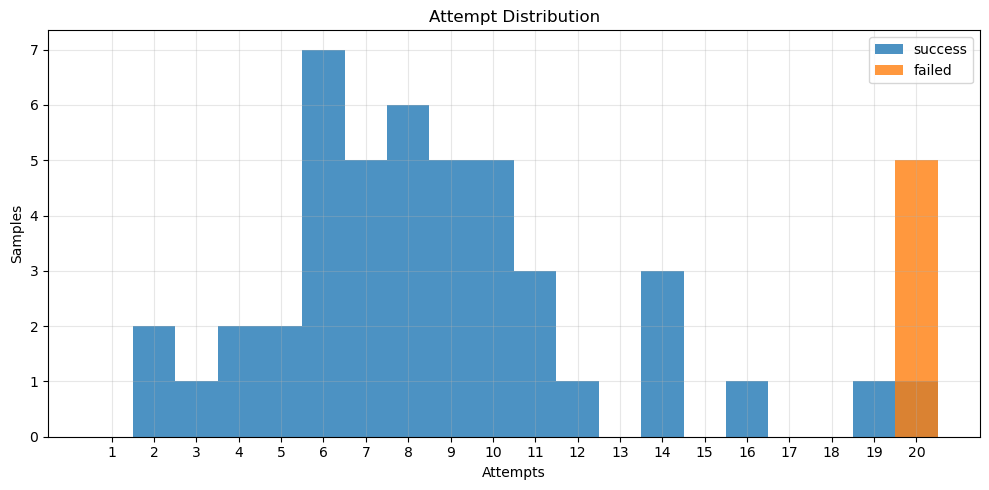

In [12]:
# Attempt Distribution

import matplotlib.pyplot as plt

per_sample = samples.groupby('sample').agg(
    total_attempts=('total_attempts', 'first'),
    final_status=('final_status', 'first')
).reset_index()

success = per_sample[per_sample['final_status'] == 'success']['total_attempts']
failed  = per_sample[per_sample['final_status'] != 'success']['total_attempts']

bins = range(1, per_sample['total_attempts'].max() + 2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(success, bins=bins, align='left', label='success', alpha=0.8)
ax.hist(failed,  bins=bins, align='left', label='failed',  alpha=0.8)
ax.set_xlabel('Attempts')
ax.set_ylabel('Samples')
ax.set_title('Attempt Distribution')
ax.set_xticks(range(1, per_sample['total_attempts'].max() + 1))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Similarity

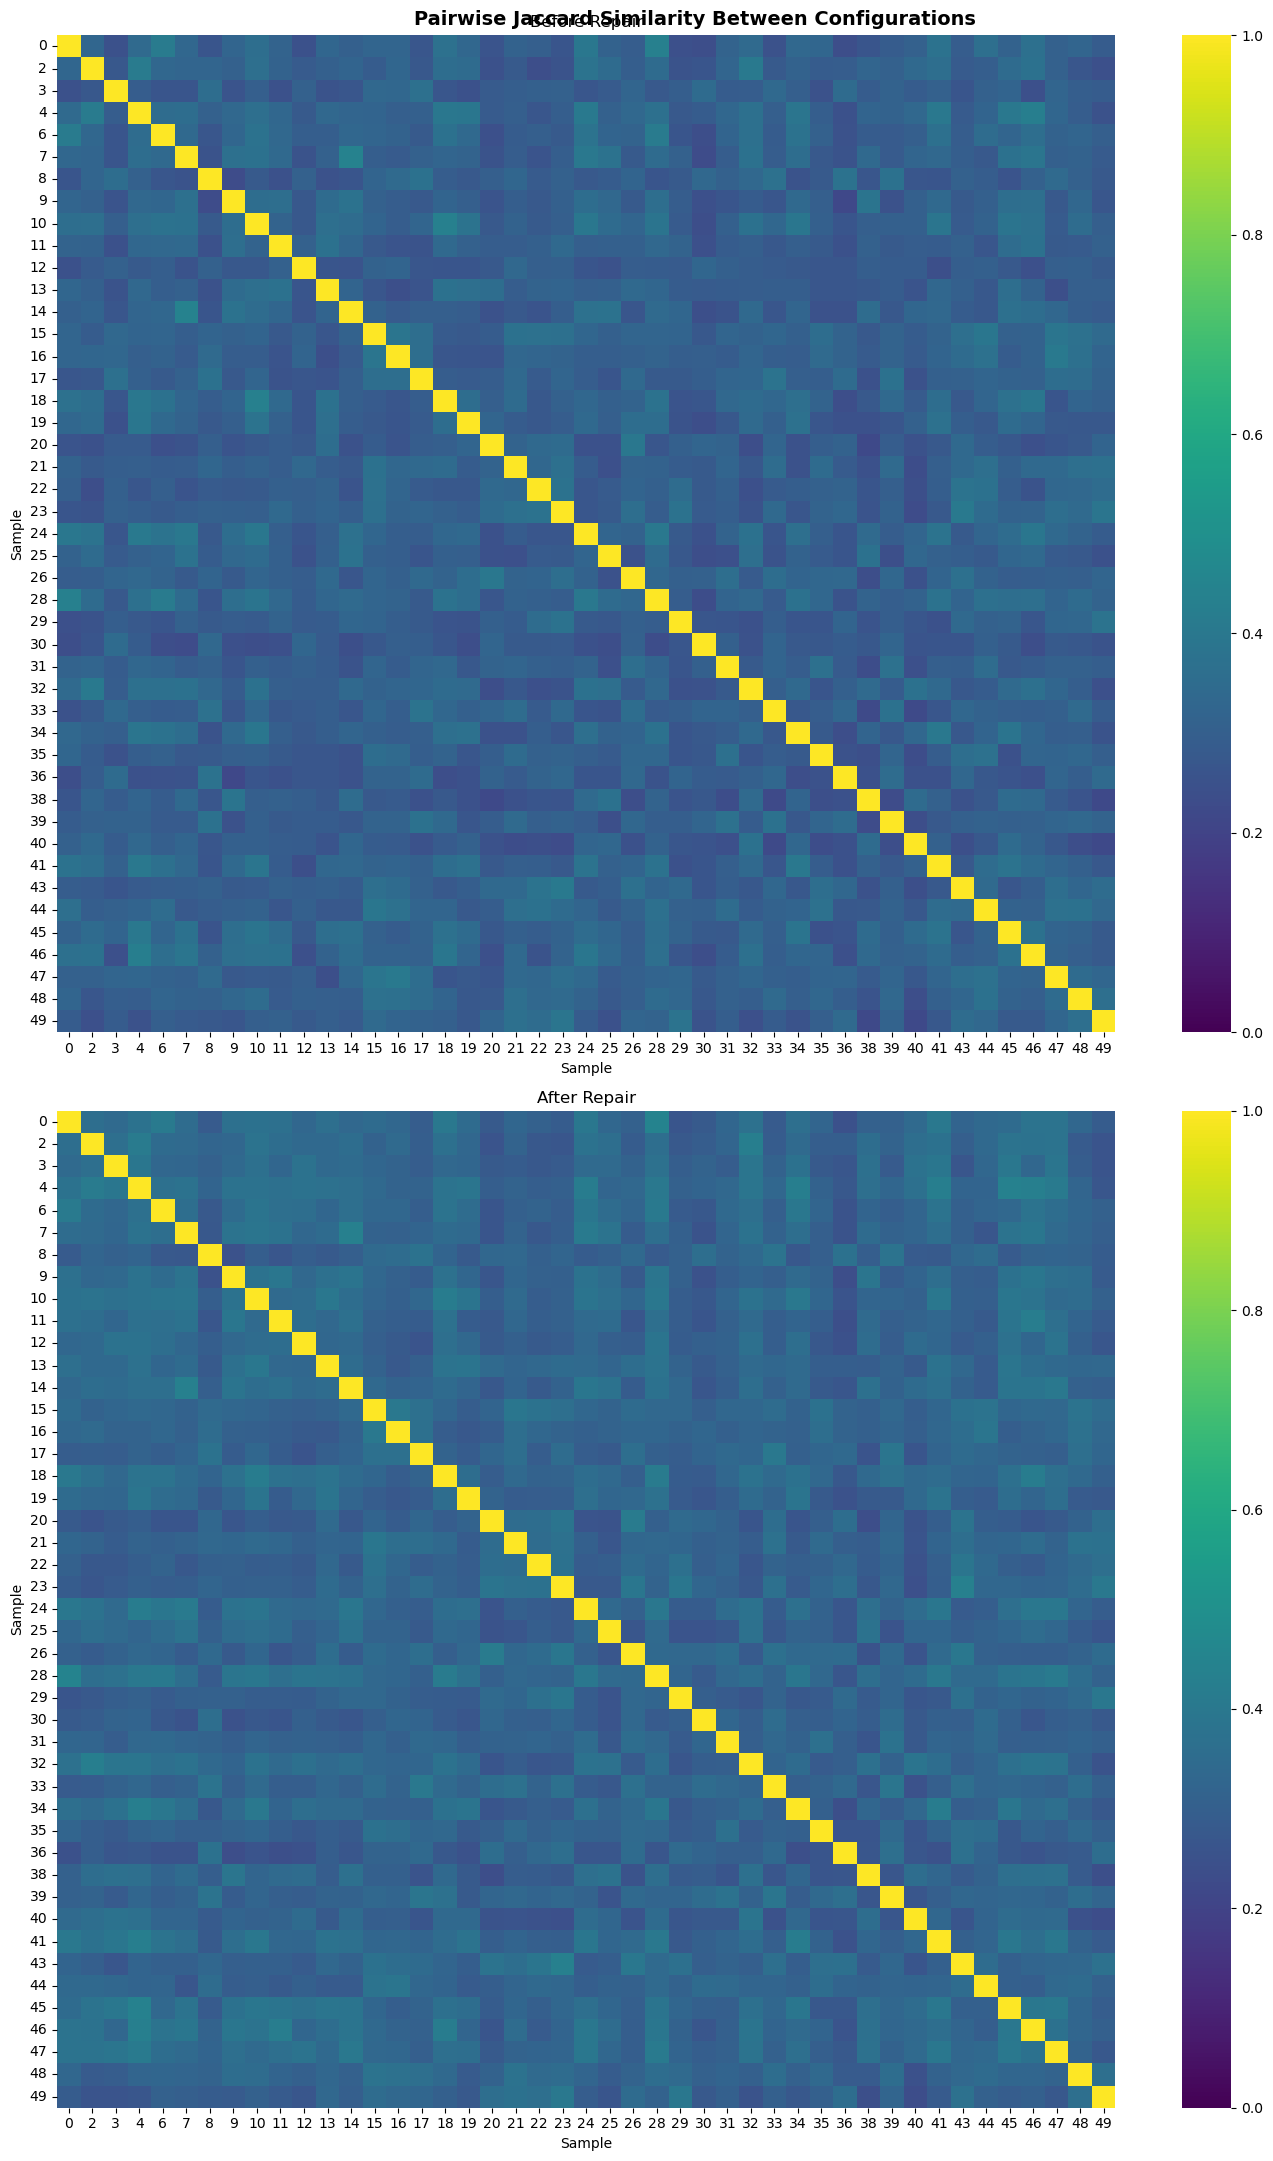

              Mean     Std     Min     Max
Before      0.3067  0.0402  0.2181  0.4384
After       0.3255  0.0392  0.2336  0.4466


In [18]:
# Jaccard Similarity Between Configurations: Before and After Repair

import seaborn as sns
import numpy as np

def parse_config(path):
	enabled = set()
	with open(path) as f:
		for line in f:
			line = line.strip()
			if not line or line.startswith('#'):
				continue
			if '=' in line:
				enabled.add(line.split('=')[0])
	return enabled

def jaccard(a, b):
	return len(a & b) / len(a | b) if (a | b) else 1.0

orig_sets    = {}
config_sets  = {}
for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
	orig_path     = f'{sample_dir}/.config'
	repaired_path = f'{sample_dir}/agent_repair/repaired.config'
	if not os.path.exists(orig_path) or not os.path.exists(repaired_path):
		continue
	name = os.path.basename(sample_dir)
	orig_sets[name]   = parse_config(orig_path)
	config_sets[name] = parse_config(repaired_path)

names = sorted(config_sets, key=lambda x: int(x.split('_')[1]))
n     = len(names)
labels = [x.replace('sample_', '') for x in names]

before_matrix = np.array([[jaccard(orig_sets[a],   orig_sets[b])   for b in names] for a in names])
after_matrix  = np.array([[jaccard(config_sets[a], config_sets[b]) for b in names] for a in names])

sim_matrix = after_matrix

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 22))

sns.heatmap(
	before_matrix, ax=ax_top, vmin=0, vmax=1, cmap='viridis',
	xticklabels=labels, yticklabels=labels,
)
ax_top.set_title('Before Repair')
ax_top.set_xlabel('Sample')
ax_top.set_ylabel('Sample')

sns.heatmap(
	after_matrix, ax=ax_bot, vmin=0, vmax=1, cmap='viridis',
	xticklabels=labels, yticklabels=labels,
)
ax_bot.set_title('After Repair')
ax_bot.set_xlabel('Sample')
ax_bot.set_ylabel('Sample')

plt.suptitle('Pairwise Jaccard Similarity Between Configurations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

before_upper = before_matrix[np.triu_indices(n, k=1)]
after_upper  = after_matrix[np.triu_indices(n, k=1)]

print(f'{"":10s} {"Mean":>7} {"Std":>7} {"Min":>7} {"Max":>7}')
print(f'{"Before":10s} {before_upper.mean():7.4f} {before_upper.std():7.4f} {before_upper.min():7.4f} {before_upper.max():7.4f}')
print(f'{"After":10s} {after_upper.mean():7.4f} {after_upper.std():7.4f} {after_upper.min():7.4f} {after_upper.max():7.4f}')


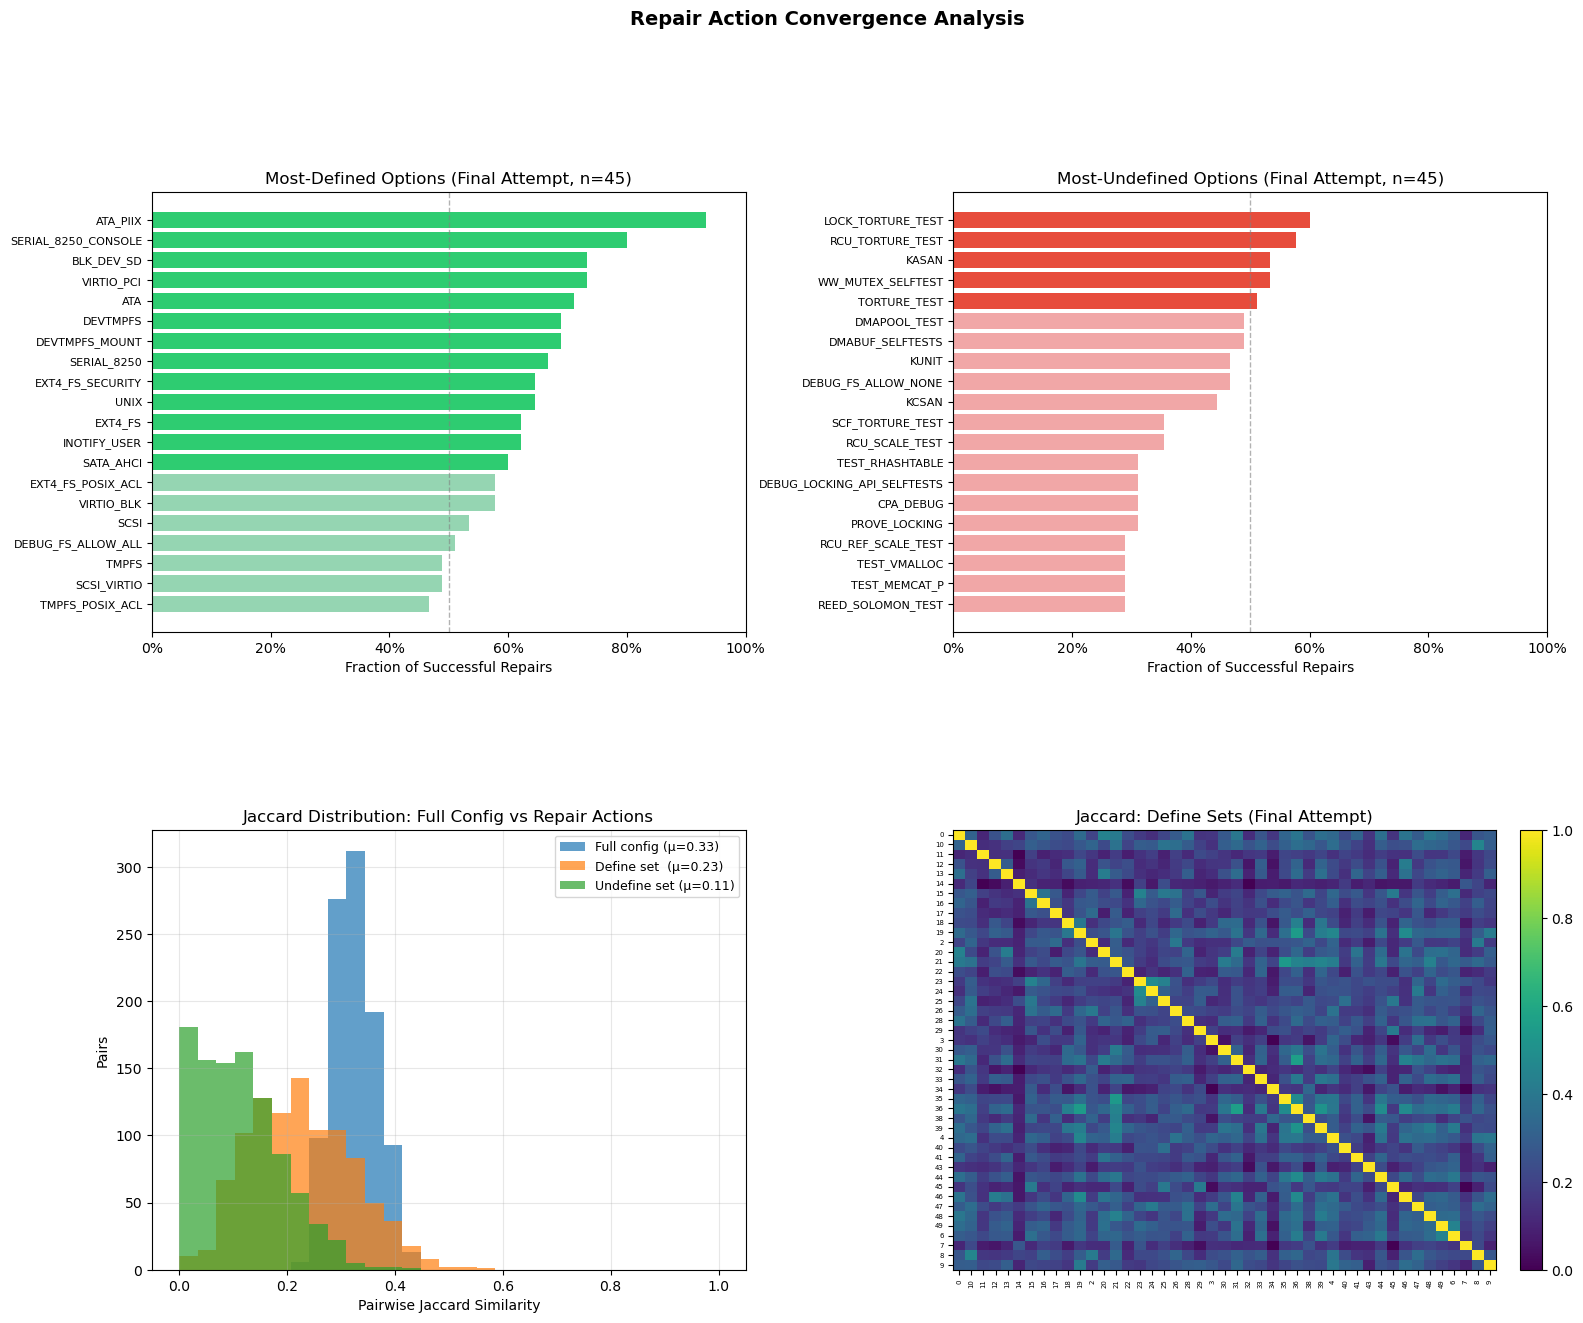

In [14]:
# Repair Action Convergence

from collections import Counter

last_defines = {}
last_undefines = {}

for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
	spath = f'{sample_dir}/agent_repair/summary.json'
	if not os.path.exists(spath):
		continue
	with open(spath) as f:
		data = json.load(f)
	if data['summary']['status'] != 'success':
		continue
	name = os.path.basename(sample_dir)
	changes = data['attempts'][-1].get('changes', {})
	last_defines[name]   = set(changes.get('define',   []))
	last_undefines[name] = set(changes.get('undefine', []))

n_success = len(last_defines)
names_s   = sorted(last_defines)

def_counter = Counter()
und_counter = Counter()
for d in last_defines.values():   def_counter.update(d)
for u in last_undefines.values(): und_counter.update(u)

TOP = 20
top_def = def_counter.most_common(TOP)
top_und = und_counter.most_common(TOP)

def_jac = np.array([[jaccard(last_defines[a],   last_defines[b])   for b in names_s] for a in names_s])
und_jac = np.array([[jaccard(last_undefines[a], last_undefines[b]) for b in names_s] for a in names_s])

def_upper  = def_jac[np.triu_indices(len(names_s), k=1)]
und_upper  = und_jac[np.triu_indices(len(names_s), k=1)]
full_upper = sim_matrix[np.triu_indices(len(names_s), k=1)]  # from prior cell

fig = plt.figure(figsize=(18, 14))
gs  = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35)

# --- top-left: define frequency ---
ax1 = fig.add_subplot(gs[0, 0])
opts_d, cnts_d = zip(*top_def)
colors_d = ['#2ecc71' if c / n_success >= 0.6 else '#95d5b2' for c in cnts_d]
bars = ax1.barh([o.replace('CONFIG_', '') for o in opts_d[::-1]],
                [c / n_success for c in cnts_d[::-1]], color=colors_d[::-1])
ax1.axvline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax1.set_xlabel('Fraction of Successful Repairs')
ax1.set_title(f'Most-Defined Options (Final Attempt, n={n_success})')
ax1.set_xlim(0, 1)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax1.tick_params(axis='y', labelsize=8)

# --- top-right: undefine frequency ---
ax2 = fig.add_subplot(gs[0, 1])
opts_u, cnts_u = zip(*top_und)
colors_u = ['#e74c3c' if c / n_success >= 0.5 else '#f1a7a7' for c in cnts_u]
ax2.barh([o.replace('CONFIG_', '') for o in opts_u[::-1]],
         [c / n_success for c in cnts_u[::-1]], color=colors_u[::-1])
ax2.axvline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.set_xlabel('Fraction of Successful Repairs')
ax2.set_title(f'Most-Undefined Options (Final Attempt, n={n_success})')
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax2.tick_params(axis='y', labelsize=8)

# --- bottom-left: Jaccard distribution comparison ---
ax3 = fig.add_subplot(gs[1, 0])
bins = np.linspace(0, 1, 30)
ax3.hist(full_upper, bins=bins, alpha=0.7, label=f'Full config (μ={full_upper.mean():.2f})')
ax3.hist(def_upper,  bins=bins, alpha=0.7, label=f'Define set  (μ={def_upper.mean():.2f})')
ax3.hist(und_upper,  bins=bins, alpha=0.7, label=f'Undefine set (μ={und_upper.mean():.2f})')
ax3.set_xlabel('Pairwise Jaccard Similarity')
ax3.set_ylabel('Pairs')
ax3.set_title('Jaccard Distribution: Full Config vs Repair Actions')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

# --- bottom-right: define set heatmap ---
ax4 = fig.add_subplot(gs[1, 1])
tick_labels = [x.replace('sample_', '') for x in names_s]
im = ax4.imshow(def_jac, vmin=0, vmax=1, cmap='viridis', aspect='auto')
ax4.set_xticks(range(len(names_s)))
ax4.set_yticks(range(len(names_s)))
ax4.set_xticklabels(tick_labels, fontsize=5, rotation=90)
ax4.set_yticklabels(tick_labels, fontsize=5)
ax4.set_title('Jaccard: Define Sets (Final Attempt)')
plt.colorbar(im, ax=ax4, fraction=0.046, pad=0.04)

plt.suptitle('Repair Action Convergence Analysis', fontsize=14, fontweight='bold', y=1.01)
plt.show()

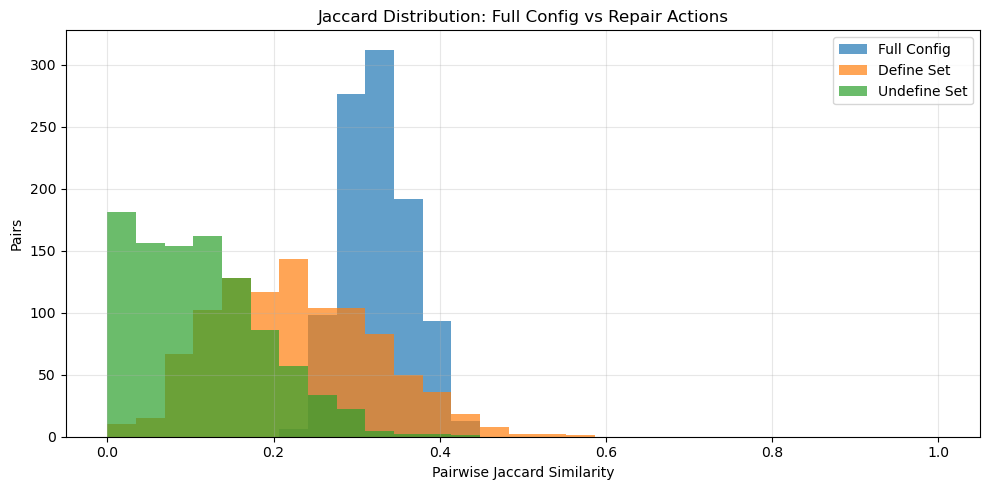

                   Mean     Std     Min     Max
Full Config      0.3255  0.0392  0.2336  0.4466
Define Set       0.2258  0.0958  0.0000  0.5660
Undefine Set     0.1115  0.0787  0.0000  0.4400


In [17]:
# Jaccard Distribution: Full Config vs Repair Actions

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 30)
ax.hist(full_upper, bins=bins, alpha=0.7, label=f'Full Config')
ax.hist(def_upper,  bins=bins, alpha=0.7, label=f'Define Set')
ax.hist(und_upper,  bins=bins, alpha=0.7, label=f'Undefine Set')
ax.set_xlabel('Pairwise Jaccard Similarity')
ax.set_ylabel('Pairs')
ax.set_title('Jaccard Distribution: Full Config vs Repair Actions')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'{"":15s} {"Mean":>7} {"Std":>7} {"Min":>7} {"Max":>7}')
print(f'{"Full Config":15s} {full_upper.mean():7.4f} {full_upper.std():7.4f} {full_upper.min():7.4f} {full_upper.max():7.4f}')
print(f'{"Define Set":15s} {def_upper.mean():7.4f} {def_upper.std():7.4f} {def_upper.min():7.4f} {def_upper.max():7.4f}')
print(f'{"Undefine Set":15s} {und_upper.mean():7.4f} {und_upper.std():7.4f} {und_upper.min():7.4f} {und_upper.max():7.4f}')

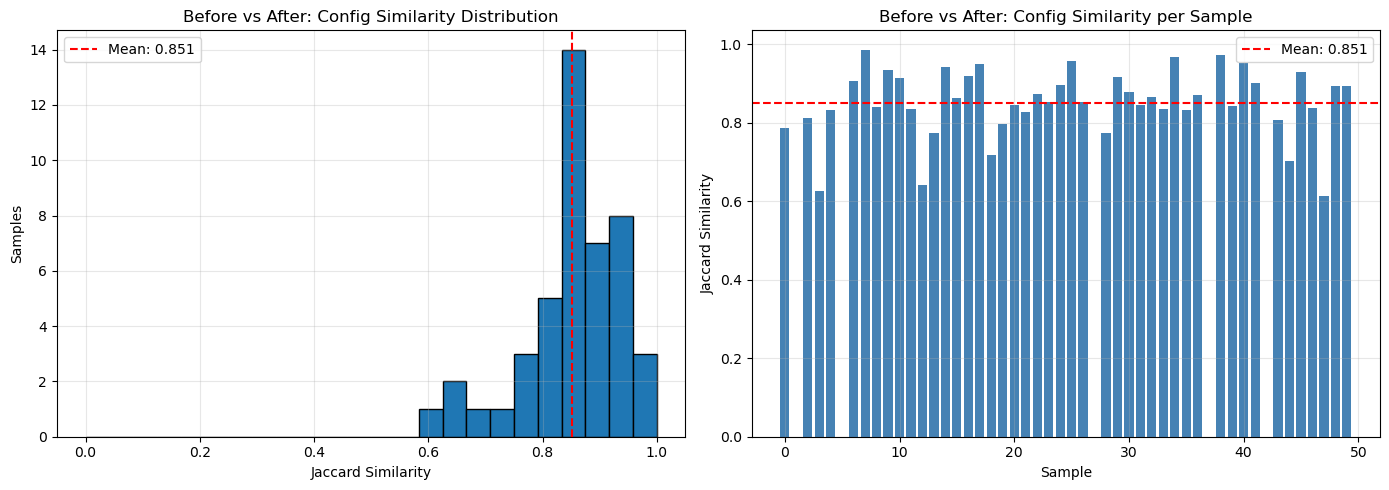

                   Mean     Std     Min     Max
Before/After     0.8513  0.0880  0.6134  0.9862


In [16]:
# Before vs After: Jaccard Similarity per Sample

before_after = []
for sample_dir in sorted(glob.glob(f'{BASE}/sample_*')):
	orig_path     = f'{sample_dir}/.config'
	repaired_path = f'{sample_dir}/agent_repair/repaired.config'
	if not os.path.exists(orig_path) or not os.path.exists(repaired_path):
		continue
	name = os.path.basename(sample_dir)
	before_after.append({
		'sample':  name,
		'jaccard': jaccard(parse_config(orig_path), parse_config(repaired_path)),
	})

ba_df = pd.DataFrame(before_after)
ba_df['sample_num'] = ba_df['sample'].str.extract(r'(\d+)$').astype(int)
ba_df = ba_df.sort_values('sample_num').reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bins = np.linspace(0, 1, 25)
ax1.hist(ba_df['jaccard'], bins=bins, edgecolor='black')
ax1.axvline(ba_df['jaccard'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f"Mean: {ba_df['jaccard'].mean():.3f}")
ax1.set_xlabel('Jaccard Similarity')
ax1.set_ylabel('Samples')
ax1.set_title('Before vs After: Config Similarity Distribution')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.bar(ba_df['sample_num'], ba_df['jaccard'], color='steelblue')
ax2.axhline(ba_df['jaccard'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f"Mean: {ba_df['jaccard'].mean():.3f}")
ax2.set_xlabel('Sample')
ax2.set_ylabel('Jaccard Similarity')
ax2.set_title('Before vs After: Config Similarity per Sample')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'{"":15s} {"Mean":>7} {"Std":>7} {"Min":>7} {"Max":>7}')
print(f'{"Before/After":15s} {ba_df["jaccard"].mean():7.4f} {ba_df["jaccard"].std():7.4f} {ba_df["jaccard"].min():7.4f} {ba_df["jaccard"].max():7.4f}')
